Khoảng cách Manhattan nhỏ nhất là: 3
Các điểm gần nhất là: (0, 0, 0) và (1, 1, 1)


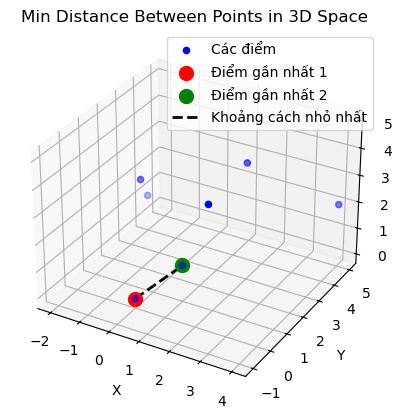

In [1]:
import math
import matplotlib.pyplot as plt

# Định nghĩa hàm tính khoảng cách Manhattan
def manhattan_distance(p1, p2):
    return abs(p1[0] - p2[0]) + abs(p1[1] - p2[1]) + abs(p1[2] - p2[2])

# Hàm phụ để tìm khoảng cách nhỏ nhất trong dải và lưu lại các điểm
def strip_closest(strip, d_min):
    min_d = d_min
    closest_points = (None, None)

    strip.sort(key=lambda point: point[1])  # Sắp xếp theo tọa độ y
    
    # So sánh mỗi điểm với điểm tiếp theo trong cửa sổ nhỏ trong dải
    for i in range(len(strip)):
        for j in range(i + 1, len(strip)):
            if abs(strip[j][1] - strip[i][1]) >= min_d:
                break
            distance = manhattan_distance(strip[i], strip[j])
            if distance < min_d:
                min_d = distance
                closest_points = (strip[i], strip[j])
    
    return min_d, closest_points

# Hàm đệ quy để tìm khoảng cách Manhattan nhỏ nhất
def closest_util(points_sorted_by_x):
    n = len(points_sorted_by_x)
    
    # Trường hợp cơ bản: nếu có 2 hoặc 3 điểm, tính khoảng cách trực tiếp
    if n <= 3:
        min_dist = float('inf')
        closest_points = (None, None)
        for i in range(n):
            for j in range(i + 1, n):
                distance = manhattan_distance(points_sorted_by_x[i], points_sorted_by_x[j])
                if distance < min_dist:
                    min_dist = distance
                    closest_points = (points_sorted_by_x[i], points_sorted_by_x[j])
        return min_dist, closest_points

    # Chia tập điểm thành hai nửa
    mid = n // 2
    mid_point = points_sorted_by_x[mid]

    # Đệ quy tìm khoảng cách nhỏ nhất ở nửa trái và nửa phải
    d_left, closest_left = closest_util(points_sorted_by_x[:mid])
    d_right, closest_right = closest_util(points_sorted_by_x[mid:])
    
    # Tìm khoảng cách nhỏ nhất
    d_min = min(d_left, d_right)
    closest_points = closest_left if d_min == d_left else closest_right

    # Tạo một dải các điểm gần đường chia
    strip = []
    for point in points_sorted_by_x:
        if abs(point[0] - mid_point[0]) < d_min:
            strip.append(point)

    # Tìm khoảng cách nhỏ nhất trong dải
    strip_distance, strip_points = strip_closest(strip, d_min)
    if strip_distance < d_min:
        d_min = strip_distance
        closest_points = strip_points

    return d_min, closest_points

# Hàm chính để tìm khoảng cách Manhattan nhỏ nhất
def closest(points):
    points_sorted_by_x = sorted(points, key=lambda point: point[0])  # Sắp xếp các điểm theo tọa độ x
    return closest_util(points_sorted_by_x)

# Hàm vẽ hình minh họa
def plot_points_and_closest(points, closest_points):
    # Tách tọa độ x, y, z từ các điểm
    x, y, z = zip(*points)
    
    # Tạo hình 3D
    fig = plt.figure()
    ax = fig.add_subplot(111, projection='3d')
    
    # Vẽ các điểm
    ax.scatter(x, y, z, color='b', label='Các điểm')

    # Vẽ các điểm có khoảng cách nhỏ nhất
    if closest_points[0] and closest_points[1]:
        ax.scatter(closest_points[0][0], closest_points[0][1], closest_points[0][2], color='r', s=100, label='Điểm gần nhất 1')
        ax.scatter(closest_points[1][0], closest_points[1][1], closest_points[1][2], color='g', s=100, label='Điểm gần nhất 2')
        
        # Vẽ đường nối giữa hai điểm gần nhất
        ax.plot([closest_points[0][0], closest_points[1][0]], 
                [closest_points[0][1], closest_points[1][1]], 
                [closest_points[0][2], closest_points[1][2]], color='k', linestyle='--', linewidth=2, label='Khoảng cách nhỏ nhất')
    
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    ax.legend()
    plt.title('Min Distance Between Points in 3D Space')
    plt.show()

# Ví dụ sử dụng thuật toán
def main():
    # Tập hợp điểm ví dụ trong không gian 3D
    points = [
        (-1, 2, 3),
        (3, -1, 5),
        (1, 1, 1),
        (4, 5, 2),
        (0, 0, 0),
        (2, 3, 4),
        (-2, 4, 1)
    ]

    # Tìm và in khoảng cách Manhattan nhỏ nhất
    min_distance, closest_points = closest(points)
    print(f"Khoảng cách Manhattan nhỏ nhất là: {min_distance}")
    print(f"Các điểm gần nhất là: {closest_points[0]} và {closest_points[1]}")

    # Vẽ hình minh họa
    plot_points_and_closest(points, closest_points)

# Chạy chương trình
if __name__ == "__main__":
    main()
